# AI-Based IoT Sensor Anomaly Detection — Master End-to-End Notebook

**Project:** AI-Based IoT Sensor Anomaly Detection (ESP32 + DHT11 on `COM19` @ `115200` baud)  
**Author:** Dungu Avinash Reddy | Roll RK3P25KZA09 | Reg. 12509090  

Complete reproducible walkthrough covering:
1. Configuration (`config.yaml` + `config.py`) & live hardware specs.
2. Cleaned training baseline (`34,383` raw -> `34,374` feature rows) & quarantined anomalies (`389` rows).
3. 12 orthogonal time/session-aware features via `features/feature_engine.py`.
4. Model training & calibrated thresholds (`Isolation Forest`, `Adaptive EWMA-Z`, `Hybrid`, `One-Class SVM`, `LOF`, `Z-Score`).
5. Internal benchmarks (`Test`, `Pilot`, `Eval Suite` incl. live `COM19` 2026-11-10 readings) and isolated external benchmarks (`UCI #357`, `IoTsec Room-Climate`).

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'config.yaml').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import config
print(f'Project root: {PROJECT_ROOT}')
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from features.feature_engine import MODEL_FEATURE_COLS, apply_gated_persistence, compute_adaptive_ewma_z

iso = joblib.load(config.model_dir / 'iforest.joblib')
scaler = joblib.load(config.model_dir / 'scaler.joblib')
thresholds = json.loads((config.model_dir / 'thresholds.json').read_text(encoding='utf-8'))
eval_summary = json.loads((config.model_dir / 'evaluation_summary.json').read_text(encoding='utf-8'))

print('Loaded production IsolationForest + StandardScaler')
print('Training rows :', thresholds['training_rows'])
print('Features count:', len(thresholds['feature_cols']))
print('IF threshold  :', round(thresholds['iforest_threshold'], 6), '| EWMA-Z th:', thresholds['ewma_zscore_threshold'])

Project root: c:\Users\Avinash Reddy\OneDrive\Desktop\Iot anomaly detection
Loaded production IsolationForest + StandardScaler
Training rows : 34374
Features count: 12
IF threshold  : -0.216569 | EWMA-Z th: 3.5


## Benchmark Comparison Across Test, Pilot & Multi-Fault Eval Suite

In [2]:
for ds_name, metrics_map in eval_summary['datasets'].items():
    df_m = pd.DataFrame(metrics_map).T[['rows', 'positives', 'precision', 'recall', 'f1', 'pr_auc', 'roc_auc', 'fp', 'fn', 'events_caught', 'events_total']]
    print(f'\n=== {ds_name.upper()} ===')
    print(df_m.to_string())

print('\n=== EVAL SUITE CATEGORY BREAKDOWN (Incl. Live COM19 2026-11-10) ===')
print(pd.DataFrame(eval_summary['eval_suite_breakdown']).T.to_string())


=== TEST ===
                        rows  positives  precision  recall      f1  pr_auc  roc_auc   fp   fn  events_caught  events_total
Z-Score Baseline        55.0       10.0     1.0000     0.7  0.8235  0.9833   0.9978  0.0  3.0            1.0           1.0
Adaptive EWMA-Z         55.0       10.0     1.0000     0.7  0.8235  1.0000   1.0000  0.0  3.0            1.0           1.0
Isolation Forest (Raw)  55.0       10.0     0.9091     1.0  0.9524  0.9909   0.9978  1.0  0.0            1.0           1.0
Isolation Forest        55.0       10.0     0.9091     1.0  0.9524  0.9909   0.9978  1.0  0.0            1.0           1.0
Hybrid (IF + EWMA-Z)    55.0       10.0     0.9091     1.0  0.9524  0.9909   0.9978  1.0  0.0            1.0           1.0
One-Class SVM           55.0       10.0     0.6250     1.0  0.7692  0.7143   0.9556  6.0  0.0            1.0           1.0
LOF (Novelty)           55.0       10.0     0.5882     1.0  0.7407  0.9622   0.9911  7.0  0.0            1.0           1.0

=

## Isolated External Domain Benchmarks (`UCI #357` & `IoTsec Room-Climate`)
Evaluated using completely separate domain scalers and EWMA-Z calibration — zero leakage with the ESP32 production artifacts.

In [3]:
for ext_name, ext_info in eval_summary.get('external_benchmarks', {}).items():
    print(f'\n=== {ext_name} (train={ext_info["train_rows"]}, test={ext_info["test_rows"]}, anomalies={ext_info["anomalies"]}) ===')
    print(pd.DataFrame(ext_info['models']).T.to_string())


=== UCI_Occupancy_357 (train=3757, test=1999, anomalies=400) ===
                      precision  recall      f1  pr_auc  roc_auc    fp     fn
Z-Score Baseline         0.9443   0.720  0.8170  0.8603   0.8796  17.0  112.0
Adaptive EWMA-Z          1.0000   0.110  0.1982  0.9659   0.9829   0.0  356.0
Isolation Forest         0.9461   0.570  0.7114  0.9333   0.9845  13.0  172.0
Hybrid (IF + EWMA-Z)     0.9482   0.595  0.7312  0.9394   0.9866  13.0  162.0

=== IoTsec_Room_Climate (train=2044, test=2457, anomalies=490) ===
                      precision  recall      f1  pr_auc  roc_auc     fp     fn
Z-Score Baseline         0.9718  0.9837  0.9777  0.9891   0.9898   14.0    8.0
Adaptive EWMA-Z          0.5162  0.9776  0.6756  0.9824   0.9890  449.0   11.0
Isolation Forest         0.6966  0.6327  0.6631  0.7677   0.9350  135.0  180.0
Hybrid (IF + EWMA-Z)     0.5089  0.9939  0.6731  0.9966   0.9979  470.0    3.0


## Live Inference Walkthrough on `eval_suite_features_full.csv`

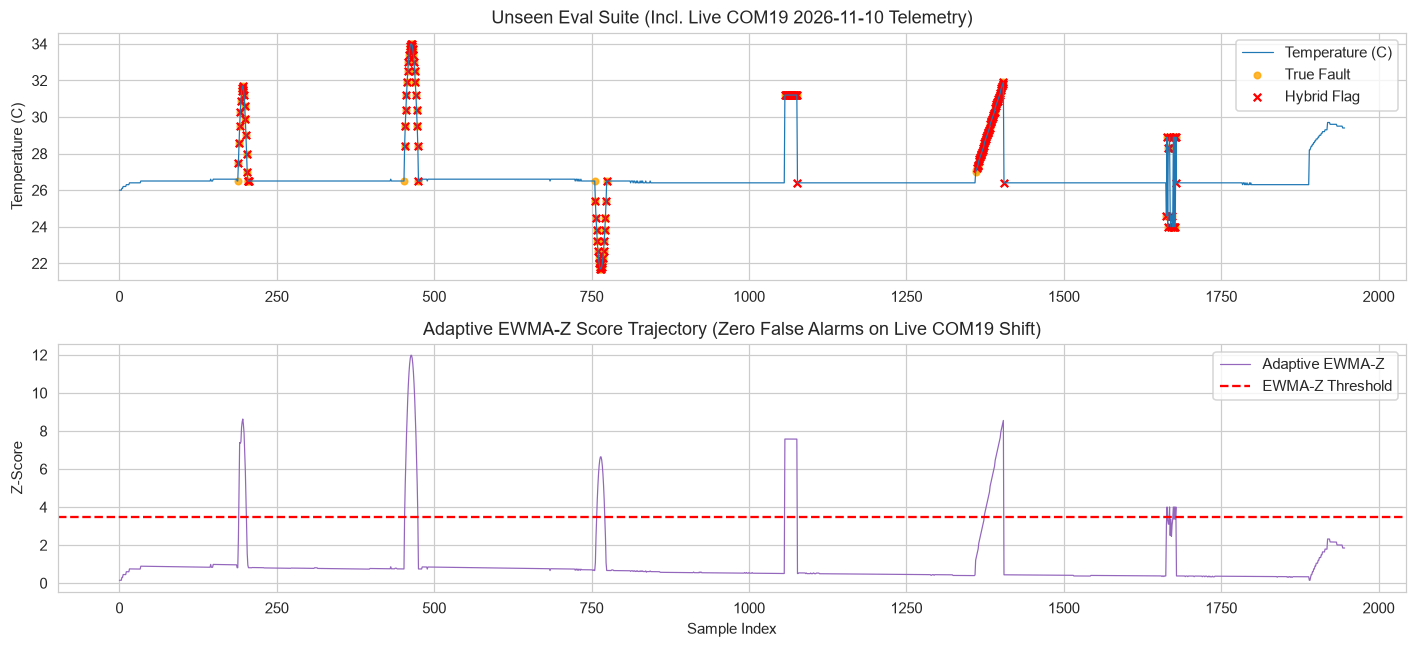

In [4]:
suite = pd.read_csv(config.features_dir / 'eval_suite_features_full.csv', parse_dates=['timestamp'])
X_scaled = scaler.transform(suite[MODEL_FEATURE_COLS])
if_scores = iso.decision_function(X_scaled)
if_flag = apply_gated_persistence(if_scores < thresholds['iforest_threshold'], suite['session_id'].to_numpy(), features_df=suite)
ewma_z = compute_adaptive_ewma_z(suite, thresholds['ewma_temp_std'], thresholds['ewma_hum_std'])
hybrid_flag = if_flag | (ewma_z > thresholds['ewma_zscore_threshold'])

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=False)
x_idx = np.arange(len(suite))
axes[0].plot(x_idx, suite['temperature'], label='Temperature (C)', color='tab:blue', linewidth=0.8)
anom_idx = x_idx[suite['label'] == 1]
det_idx = x_idx[hybrid_flag]
axes[0].scatter(anom_idx, suite.loc[suite['label'] == 1, 'temperature'], color='orange', s=18, label='True Fault', alpha=0.8)
axes[0].scatter(det_idx, suite.loc[hybrid_flag, 'temperature'], marker='x', color='red', s=24, label='Hybrid Flag')
axes[0].set_title('Unseen Eval Suite (Incl. Live COM19 2026-11-10 Telemetry)')
axes[0].set_ylabel('Temperature (C)')
axes[0].legend()

axes[1].plot(x_idx, ewma_z, label='Adaptive EWMA-Z', color='tab:purple', linewidth=0.8)
axes[1].axhline(thresholds['ewma_zscore_threshold'], color='red', linestyle='--', label='EWMA-Z Threshold')
axes[1].set_title('Adaptive EWMA-Z Score Trajectory (Zero False Alarms on Live COM19 Shift)')
axes[1].set_ylabel('Z-Score')
axes[1].set_xlabel('Sample Index')
axes[1].legend()

plt.tight_layout()
plt.show()